# PTM3D tutorial 03 — an asteroid on a Keplerian orbit

PTM3D's **generic-body** path: a body that is not one of the built-in planets or
moons, placed on an analytic two-body orbit with a spin state you choose. It
needs no planetary ephemeris and no shape file — the orbit is propagated from
its elements and the shape is a synthetic icosphere generated at run time. The
only external data is the universal leapseconds kernel (about 5 kB), because the
config's UTC `start_time` is parsed by SPICE.

The physics the notebook is built around is **thermal inertia**,
$\Gamma = \sqrt{k \rho c_p}$: the property asteroid radiometry actually
measures, through how far a surface's temperature lags a fast insolation cycle.
Two otherwise identical runs at $\Gamma = 100$ and 200 SI show the
signature, and section 4 uses them to show which config keys a generic
body reads — the opposite set from the built-in bodies of tutorials 01
and 02.

**Cost:** three CPU-only runs of about 20 s each on a 1,280-face
icosphere, two rotations of output after 50 rotations of spin-up.

**Related:** [01](01_moon_diurnal.ipynb) for a built-in body, and for the run
reader and output format used here without re-deriving them;
[04](04_asteroid_spice.ipynb) for the same path on a real ephemeris and a real
shape model.

In [1]:
from ptm import paths, run as engine

CONFIG = "examples/quickstart_asteroid_diurnal.yaml"
CHECK = "examples/quickstart_asteroid_diurnal_ti200_check.yaml"
pre = paths.preflight([CONFIG, CHECK, "data/kernels/lsk/naif0012.tls"],
                      engine="ptm_thermal_sim")
print(pre)
pre.raise_if_missing()

found    /Users/paha3326/Projects/ptm-tut-thermophys/build-cpu/bin/ptm_thermal_sim
found    examples/quickstart_asteroid_diurnal.yaml
found    examples/quickstart_asteroid_diurnal_ti200_check.yaml
found    data/kernels/lsk/naif0012.tls

Repo root: /Users/paha3326/Projects/ptm-tut-thermophys
Engine:    /Users/paha3326/Projects/ptm-tut-thermophys/build-cpu/bin/ptm_thermal_sim


<Report 4/4 found>

## 1. Run it

About 20 s on a many-core workstation. `body_radius_km` tells the reader which
length unit `mesh.ply` is in — the file itself does not record one, and stating
it is better than inferring it from magnitude.

In [2]:
run = engine.run_engine(pre.root / CONFIG, echo=True)
base = run.results(body_radius_km=5.0)

Running: /Users/paha3326/Projects/ptm-tut-thermophys/build-cpu/bin/ptm_thermal_sim --config /Users/paha3326/Projects/ptm-tut-thermophys/examples/quickstart_asteroid_diurnal.yaml
(cwd=/Users/paha3326/Projects/ptm-tut-thermophys)

╔═══════════════════════════════════════════════════════════════╗
║    *      .    *     \   ||    //      * .   .      *         ║
║       .      *     \  \  ||   //    //       .             .  ║
║  *      .       \   \  \  ☀  //    //      .      *           ║
║     .         *  \   ...-'''''-...//    *         .           ║
║           _ ... .-'''''   PTM3D     ``''-.....,__      .      ║
║   __,.-''    Planetary Thermophysical Model 3D     `'-..., _  ║
║  ═══════════════════════════════════════════════════════════  ║
║      Coupled Thermal-Illumination for Planetary Bodies        ║
╚═══════════════════════════════════════════════════════════════╝
Successfully loaded configuration from: /Users/paha3326/Projects/ptm-tut-thermophys/examples/quickstart_asteroi

Calculating illumination:  [>                                                 ] 0% | elapsed 0s
Calculating illumination:  [============>                                     ] 25% | elapsed 0s, ETA 1s


Calculating illumination:  [=========================>                        ] 50% | elapsed 0s, ETA 0s
Calculating illumination:  [=====================================>            ] 75% | elapsed 1s, ETA 0s


Calculating illumination:  [==================================================] 100% | elapsed 1s
Illumination calculation completed in 0.843 seconds.
Results:
Average total flux: 93.220130412 W/m^2
- Direct solar: 93.220130412 W/m^2
- Primary reflected: 0.000000000 W/m^2
- Primary IR: 0.000000000 W/m^2
Maximum total flux: 186.682085782 W/m^2
- Direct solar: 186.682085782 W/m^2
- Primary reflected: 0.000000000 W/m^2
- Primary IR: 0.000000000 W/m^2
Minimum flux (non-zero): 0.000001286 W/m^2
Ray tracing computation completed in 0.846 seconds (846 ms)
[solar-const] incidence albedo uses the INSTANTANEOUS heliocentric solar constant (PTM-28 fix, default ON); S_inst range [186.7, 186.7] W/m^2
Verifying extracted illumination data:
Expected array size: 1280 * 2592 = 3317760
Illumination array size: 3317760
Direct solar array size: 3317760
Times array size: 2592
Non-zero illumination values: 1660973 out of 3317760
Average non-zero illumination: 93.220 W/m^2
Using 4 OpenMP threads for thermal 

SIMD Batch thermal [>                                                 ] 0% | elapsed 0s


SIMD Batch thermal [============>                                     ] 25% | elapsed 1s, ETA 3s


... (2 outputs left out)

SIMD Batch thermal [==================================================] 100% | elapsed 5s
SIMD Batch thermal computation completed in 5.116 seconds (5116 ms)
SIMD Batch thermal models completed successfully!
[Memory] Released combined illumination array (keeping per-component arrays for export)
[Integration] Statistics interval
Start (abs step): 2400
Duration (steps): 192
Body positions written to output/quickstart_asteroid_diurnal/body_positions.csv
Using binary output format for data files
[exportDataAsBinary] Starting binary export
Faces=1280 time_steps=192 components: illumination direct_solar primary_reflected primary_ir temperature
Progress 1/192


Progress 55/192


Progress 109/192


Progress 163/192
Progress 192/192
Export complete: 192/192
Binary export completed successfully!
Data successfully written in binary format to: output/quickstart_asteroid_diurnal
[Statistics] Exporting statistics over integration window...
[exportStatisticsBinary] Computing and exporting statistics...
Face count: 1280
Time steps: 192
Computing illumination statistics...
Computing direct solar statistics...
Computing primary reflected statistics...
Computing primary IR statistics...
Computing temperature statistics...
[exportStatisticsBinary] Statistics export completed successfully!
[Statistics] Exported to output/quickstart_asteroid_diurnal/statistics
[albedo] PTM-107(a) effective surface albedo (flux-weighted over the DIRECT beam, the value the BC absorbed with): global A_eff = 0.05 over 1226/1280 ever-lit faces; per-face -> output/quickstart_asteroid_diurnal/statistics/effective_albedo.bin (uint32 n + float32[1280], NaN where never lit).
Reduced over the INTEGRATION window, abs step

## 2. The first look

One output step from the second, settled rotation.

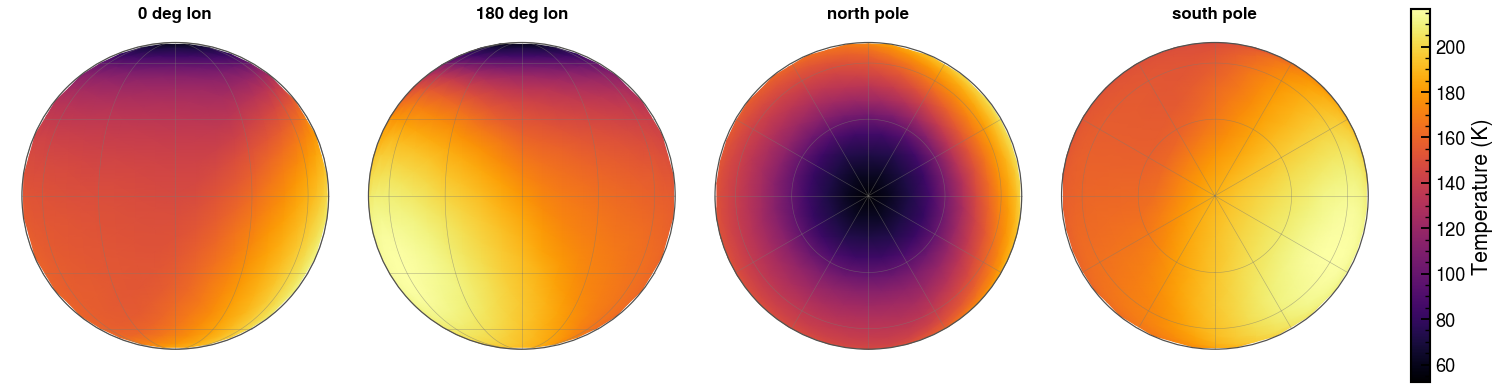

In [3]:
fig = base.plot_globes("temperature", step=120)

A warm afternoon side, a cold night side — and a strong north/south asymmetry
that is worth pinning down before anything else, because it sets which faces the
rest of the notebook may use.

In [4]:
import numpy as np

subsolar = np.array([base.subsolar_latlon(s) for s in base.steps("temperature")])
print(f"sub-solar latitude : {subsolar[:, 0].min():+.2f} to {subsolar[:, 0].max():+.2f} deg")
print(f"sub-solar longitude: {subsolar[:, 1].min():+.0f} to {subsolar[:, 1].max():+.0f} deg "
      f"over {len(subsolar)} steps")

sub-solar latitude : -23.02 to -23.00 deg
sub-solar longitude: -178 to +178 deg over 192 steps


The sub-solar latitude is fixed at about **-23 deg** for the whole run, and only
the longitude moves. Two consequences: the only time dependence on this
sub-day timescale is the diurnal cycle, which is what the notebook wants; and
the poles are not equivalent. Above +67 deg latitude the Sun never rises, and
below -67 deg it never sets, which is the asymmetry in the globes.

That fixed sub-solar latitude comes from the geometry the config specifies: the
spin pole is given in the equatorial frame (`pole_dec_deg: 90`) while the orbit
is defined by elements inclined to that frame, leaving an effective obliquity of
about 23 deg rather than zero. The config's own header comment calls it zero
obliquity; the run above is the authority. Nothing downstream depends on the
value being zero — only on its being constant — but the polar faces are a
permanent-illumination and permanent-shadow edge case, so every comparison below
uses an equatorial band instead of whole-body extrema.

## 3. The config

[`examples/quickstart_asteroid_diurnal.yaml`](../../../examples/quickstart_asteroid_diurnal.yaml)
as shipped:

In [5]:
print((pre.root / CONFIG).read_text())

# PTM3D quickstart: a generic-body (Keplerian) asteroid diurnal run on a small
# icosphere (ico3, 1280 faces).
#
# Laptop-friendly (CPU-only, <1 GB RAM; ~23 s measured on an 8-core machine
# with thermal.threads=4, well under a minute of wall time).
# SELF-CONTAINED: unlike the Moon/Horizons quickstarts, this run needs NO
# external data at all — no SPICE kernels, no DEM, no albedo/property maps.
# The body is fictional (there is no real "Quickstart Asteroid"); its orbit is
# propagated analytically (Keplerian two-body) and its shape is a synthetic
# icosphere, so nothing outside this file is fetched or required.
#
# All paths are relative — run FROM THE REPOSITORY ROOT:
#
#     ./build/bin/ptm_thermal_sim --config examples/quickstart_asteroid_diurnal.yaml
#
# Outputs land in output/quickstart_asteroid_diurnal/ (per-face statistics +
# per-timestep binaries). See docs/tutorials/notebooks/03_asteroid_thermal.ipynb
# for a full walkthrough of the outputs.
#
# ----------------------------

**Shape, orbit, spin.** A level-3 icosphere (1,280 faces) of radius 5 km, on a
circular orbit at $a = 2.7$ AU — a generic mid-main-belt placement, not a real
object. The solar constant there is $1361/2.7^2 \approx 187$ W/m², 14% of
Earth's, which is why asteroid surface properties are measured by thermal
infrared radiometry rather than by visible photometry: these bodies are cold
and, being dark, comparatively IR-bright. The spin period is 5 h, a fast
rotator.

**Thermal inertia.** The config sets `ks = kd = 0.008333` W/m/K,
`rhos = rhod = 1500` kg/m³, `cp0 = 800` J/kg/K and `chi = 0`, giving

$$\Gamma = \sqrt{0.008333 \times 1500 \times 800} = 100.0\ \mathrm{SI\ exactly},$$

constant in depth *and* in temperature: `ks == kd` and `rhos == rhod` collapse
the usual two-layer regolith profile to one homogeneous slab, so there is
exactly one number to reason about. 100 SI sits in the regolith range — loose
lunar-like regolith is near 50, bare rock and boulders 400-2500. Values far
outside roughly 32-316 SI can hit numerical edge cases on this path: very low
thermal inertia gives a sub-millimeter skin depth, very high gives slow
equilibration.

**Where the keys must live.** For a generic body, plain property names in a
top-level `thermophysical:` block (`ks`, `kd`, `rhos`, `cp0`, `Qb`, `chi`,
`albedo`, ...) are **not read** — only `generic_body.surface:` is. See
[`docs/KNOWN_LIMITATIONS.md`](../../KNOWN_LIMITATIONS.md). This config therefore
carries only `use_default_albedo: false` at the top level.

## 4. Changing a thermophysical property on a generic body

This is the mirror image of tutorial 01. There, on a built-in body, the
plainly-named properties are read by nothing and a change has to go through
`thermophysical.*_override`, `constant_thermal_inertia`, a per-face map or a
command-line flag. Here the whole `generic_body.surface:` block is the
authority, and every key in it is live: `albedo`, `emissivity`, `ks`, `kd`,
`rhos`, `rhod`, `cp0`, `H`, `Qb` and `chi`. Editing any of them changes the
answer. That is the reason to define a body this way even when a built-in one
would nearly do.

The trap that survives the move is the *location*. The same names at top level
under `thermophysical:` are still read by nothing — `thermophysical.ks` next to
`generic_body.surface.ks` leaves the run byte-identical — and the engine says
so in one line, `[config] WARNING: ... are read by nothing and have NO effect`.
Tutorial 01, section 10 shows `ptm.engine_config.unknown_keys` catching the
same class of mistake before a run starts.

The `*_override` channel is not exclusive to built-in bodies: it works here too,
and it is the only channel that prints what the solver took delivery of. Both
routes appear below.

In [6]:
banner = run.lines.index(next(l for l in run.lines if l.startswith("Using generic body")))
print("\n".join(run.lines[banner:banner + 10]))

Using generic body: Quickstart Asteroid
Semi-major axis: 2.7 AU
Eccentricity: 0
Spin period: 5 hours
Solar constant: 186.694 W/m^2
Synodic day: 5.00064 hours
Albedo: 0.05
Emissivity: 0.95
Body radius: 5 km
Ephemeris: Keplerian


It confirms the body name, orbit, spin period, solar constant, albedo,
emissivity, radius and ephemeris mode — and mentions `ks`, `kd`, `rhos`, `rhod`,
`cp0`, `Qb` and `chi` nowhere. A `generic_body.surface` edit has no line of its
own to grep, so confirming one takes the two habits from tutorial 01 in the
order that suits this path:

1. **Two runs must not agree.** A checksum over
   `statistics/temperature_max.bin` separates a real change from an edit that
   went nowhere.
2. **The physics must move the right way.** Higher thermal inertia must damp
   the diurnal swing toward the mean. A change of the wrong sign is a change
   that reached the solver as something other than what was meant.

`examples/quickstart_asteroid_diurnal_ti200_check.yaml` is this config with `ks`
and `kd` scaled by four, so $\Gamma = 200$ SI. The third run takes the same step
through `thermophysical.ks_override`, which does print a line.

In [7]:
import hashlib

from ptm import Sweep

override = Sweep(pre.root / CONFIG,
                 grid={"thermophysical.ks_override": [0.033333333]},
                 overrides={"thermophysical.kd_override": 0.033333333},
                 outdir=pre.root / "output/asteroid_ks_override",
                 results_kwargs={"body_radius_km": 5.0})
override.run()
check = engine.run_engine(pre.root / CHECK, show=("Simulation completed in",)
                          ).results(body_radius_km=5.0)

band = base.faces_in_band(-10.0, 10.0)
print(f"\nequatorial band: {band.size} of {base.n_faces} faces\n")
for tag, res in (("100 SI, as shipped        ", base),
                 ("200 SI, generic_body.surface", check),
                 ("200 SI, thermophysical.*_override", override.points[0].results)):
    hi = res.stat("temperature", "max")[band].mean()
    lo = res.stat("temperature", "min")[band].mean()
    digest = hashlib.md5(
        (res.path / "statistics" / "temperature_max.bin").read_bytes()).hexdigest()
    print(f"  {tag:34s} Tmax {hi:6.1f} K   Tmin {lo:6.1f} K   "
          f"amplitude {hi - lo:5.1f} K   {digest[:8]}")
print("\n" + next(l for l in (override.points[0].dir / "engine.log").read_text().splitlines()
                  if "applied at solver:" in l))

[sweep] engine /Users/paha3326/Projects/ptm-tut-thermophys/build-cpu/bin/ptm_thermal_sim (md5 04287bb7c7fb230d31588e8a11491ac8)
[sweep] axis thermophysical.ks_override: 1 values -> config key thermophysical.ks_override


[sweep] ok   ks_override-0p0333333 (7.4 s)
[sweep] 1 complete, 0 failed, 0 skipped, 7.4 s


    Simulation completed in 7.343 seconds (7343 ms)

equatorial band: 220 of 1280 faces

  100 SI, as shipped                 Tmax  208.4 K   Tmin  146.8 K   amplitude  61.7 K   c0a82a66
  200 SI, generic_body.surface       Tmax  197.1 K   Tmin  158.8 K   amplitude  38.3 K   7255c248
  200 SI, thermophysical.*_override  Tmax  197.1 K   Tmin  158.8 K   amplitude  38.3 K   04925614

[Thermo override] applied at solver: ks 0.033333 -> 0.0333333 W/m/K; kd 0.033333 -> 0.0333333 W/m/K


The mean equatorial peak fell and the mean equatorial minimum rose — damping
toward the mean, the textbook-correct sign rather than merely a nonzero change.
The checksums differ, so the edit is not a no-op. The property reaches the
solver.

The two 200 SI arms agree in every printed digit while writing different files
— their largest per-face difference in $T_\mathrm{max}$ is $10^{-4}$ K — and
that is the useful part: `generic_body.surface.ks` and
`thermophysical.ks_override` are two spellings of one change on this path.
Prefer the surface block when the value belongs to the body's definition, and
the override when it belongs to the experiment — sweeping, or leaving the
shipped config untouched. Only the override announces the value the solver
used, so a sweep over the surface block leans harder on the checksum.

## 5. The thermal-inertia signature

The curve below is temperature against **local solar time**: the Sun's hour
angle on a 24-hour clock with local noon at 12 h, regardless of the body's
actual rotation period. For each equatorial-band face, local noon is the step at
which its `direct_solar` flux peaks — flux has no thermal inertia, so that is
exact — and its temperature samples are placed on the clock relative to its own
noon. `local_solar_time_curve` does that reduction and averages over the whole
band, so single-face triangulation quirks wash out. Which steps to feed it stays
with the caller, because "the settled rotation" is a judgment about the run;
here it is the second of the two written.

100 SI: peak at local solar time 13.25 h, amplitude 61.4 K
200 SI: peak at local solar time 13.75 h, amplitude 38.0 K


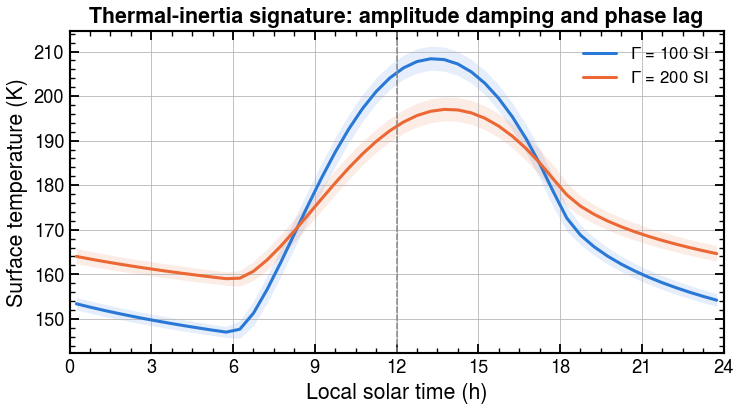

In [8]:
from ptm import plots

plt = plots.styled()
curves = {}
for tag, res in (("100 SI", base), ("200 SI", check)):
    steps = res.steps("temperature")
    curves[tag] = res.local_solar_time_curve(steps=steps[len(steps) // 2:])

fig, ax = plt.subplots(figsize=(7, 4.0))
for (tag, (lst, T, lo, hi, n_faces)), color in zip(curves.items(), ("#2a78d6", "#eb6834")):
    ax.plot(lst, T, color=color, lw=2, label=rf"$\Gamma$ = {tag}")
    ax.fill_between(lst, lo, hi, color=color, alpha=0.12, linewidth=0)
    print(f"{tag}: peak at local solar time {lst[np.argmax(T)]:.2f} h, "
          f"amplitude {T.max() - T.min():.1f} K")
ax.axvline(12, color="#898781", lw=1, ls="--")
ax.set_xlabel("Local solar time (h)")
ax.set_ylabel("Surface temperature (K)")
ax.set_title("Thermal-inertia signature: amplitude damping and phase lag")
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 3))
ax.legend(frameon=False)
ax.grid(True, linewidth=0.5)
fig.tight_layout()

Both effects are there. Doubling the thermal inertia moves the peak about half
an hour later and flattens the curve toward the mean, cutting the amplitude by
nearly 40% (Spencer et al. 1989). The shaded bands are the 25th-75th
percentile spread between faces at fixed local solar time; they are narrow, so
the band average is representative.

One subtlety worth keeping: a larger phase lag does not imply a larger absolute
morning/afternoon temperature difference. The difference
$T(\text{noon}+x) - T(\text{noon}-x)$ is positive for both runs — afternoon
warmer than the mirrored morning, the correct sign — but it is *smaller* at
200 SI, because the amplitude falls faster than the lag grows over this range.
That is why real thermophysical fits use the whole curve shape, amplitude and
phase together, rather than any single asymmetry number, to solve for $\Gamma$.

## 6. Interpretation

**What thermal inertia sets.** $\Gamma = \sqrt{k \rho c_p}$ controls how far a
diurnal thermal wave penetrates before the next day/night flip reverses it — the
skin depth $\ell_s = \sqrt{\kappa P/\pi}$, about 6.3 mm for this config at its
5 h spin. The dimensionless combination that governs the whole curve shape is
the thermal parameter

$$\Theta = \frac{\Gamma \sqrt{\omega}}{\varepsilon \sigma T_{eq}^3}$$

(Spencer, Lebofsky & Sykes 1989, with $\omega$ the rotation rate and $T_{eq}$
the zero-inertia sub-solar equilibrium temperature). $\Theta \to 0$ is an
instantaneous-equilibrium surface with a huge swing and no lag;
$\Theta \to \infty$ is perfectly conductive, with no diurnal variation at all.
The 100-to-200 SI pair is a finite step along that curve.

**The Yarkovsky connection.** Because the peak lags local noon, the asteroid
re-radiates more thermal photons from its afternoon hemisphere than an
instantaneous-equilibrium body would, and photon emission carries momentum. For
an ordinary prograde rotator the recoil has a small component along the orbital
velocity, which over millions of years drifts the semi-major axis outward
(inward for a retrograde one): the Yarkovsky effect (Bottke et al. 2006).
Thermal inertia sets its size, and both limits suppress it — no lag, or no
asymmetry left to lag — so it peaks at intermediate $\Theta$, the regime small
near-Earth asteroids often sit in. Measuring thermal inertia and modeling
Yarkovsky drift are the same problem in practice.

**Connection to observation.** Nothing here is observational, but the pipeline
is the real one: thermal-infrared photometry measures a disk-integrated flux at
one or more wavelengths and rotational phases; a thermophysical model —
structurally this same conduction solve, fit to a real shape, spin and albedo —
is run over a grid of candidate thermal inertias, and the value that reproduces
the observed flux in amplitude *and* phase is reported. Flyby and rendezvous
thermal-IR imaging measures $T$ against local time directly, the way the figure
above does.

A real thermal *lightcurve* is a different thing again, and this body cannot
show one: disk-integrated flux modulates as a non-spherical body turns a
changing silhouette toward the observer, so it is a shape effect as much as a
thermophysical one. Tutorial 04 uses a real facet shape.

## 7. Exercises

Each launches one or more further runs of about 20 s. All of them are config
edits plus the two cells above.

1. **Sweep thermal inertia.** $\Gamma \propto \sqrt{k_s}$ at fixed density and
   heat capacity, so $\Gamma =$ 32, 100, 316 SI needs
   `generic_body.surface.ks` = `kd` = 0.000853, 0.008333, 0.0833 W/m/K. Plot
   amplitude and peak local solar time against $\Gamma$ over that range; outside
   it, expect the numerical edge cases described in section 3.

2. **Sweep spin rate.** Change `generic_body.spin.period_hours` to 2 h and 10 h
   at fixed $\Gamma = 100$. What matters is $\Theta \propto \Gamma\sqrt{\omega}$,
   so a faster rotator should show *more* damping at the same thermal inertia.
   Lower `thermal.equilibration_steps_per_day` proportionally when shortening the
   period, so the per-rotation sample count does not change with it.

3. **Add eccentricity.** Set `generic_body.orbit.eccentricity: 0.2`. The
   ~10 h output window here is far too short to show any effect —
   heliocentric distance barely moves over a few hours of a 4.4-year orbit — so
   this one needs `simulation.duration_days` extended to a sizeable fraction of
   the orbital period, beyond laptop-tutorial cost. Look for a slowly drifting
   mean temperature riding on the same diurnal cycle.